# 04 · Thermal power: did it decline?

Efficiency told us how much *water* comes back. But the point of a geothermal system is the **heat**. This notebook asks:

1. **How much heat power** does the circulation produce?  (*thermal power, in megawatts*)
2. **How did it change** during the test, and what drove the change?
3. **Did it decline?**  The notebook is named *power decline* because that is the classic concern: as cold water circulates, the rock cools and the output drops. We will let the data answer, not assume.
4. **How much heat energy** did the whole test produce?
5. **How sure are we?**

> **A note on units.** Power is energy per second. **1 MW (megawatt) = 1,000 kJ every second.** We write **MWt** for *thermal* megawatts (heat), to keep it apart from *electrical* megawatts (MWe), which would be much smaller because turning heat into electricity wastes most of it.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from load import load_clean, load_flow_calibration, load_constants, load_manual_tp
from clean import temperature_offset
from analysis import (separator_conditions, mass_flows, thermal_power, thermal_power_at_separator,
                      find_plateau_start, recalibrate_through_origin, enthalpy_liquid)
from plots import apply_style, savefig, shade_window

apply_style()

d = load_clean("30s")
steady = d[d["valid_steady"]].copy()

mf = mass_flows(steady)                                   # mass flows (from notebook 03)
daily_eff = mf["efficiency"].groupby(steady.index.date).median()
plateau_start, _ = find_plateau_start(daily_eff)          # same plateau rule as notebook 03
plateau = steady.loc[str(plateau_start):]
print("Plateau window:", plateau_start, "to", plateau.index.max().date())

Plateau window: 2024-08-29 to 2024-09-04


## 1. How do we calculate thermal power?

The heat carried out of the ground by the water is simply:

$$\text{power} = \text{mass flow} \times (\text{energy per kg coming out} - \text{energy per kg going in})$$

The "energy per kg" of water is called its **enthalpy** (kJ/kg). It rises with temperature, roughly **4.2 kJ for every 1 °C** (the familiar fact that it takes a lot of energy to heat water). We read exact values from steam tables, as in notebook 03.

Let's do it step by step for the plateau, in plain numbers:

In [2]:
tp = thermal_power(steady, mf=mf)                 # thermal power for every steady row
p = tp.loc[plateau.index]

m_out = p["produced_kg_s"].median()
T_out_F = plateau["T16B_corr_F"].median()

print(f"1. Produced mass flow            : {m_out:6.1f} kg/s   (liquid + steam, from notebook 03)")
print(f"2. Producer temperature          : {T_out_F:6.0f} °F  = {(T_out_F-32)/1.8:.0f} °C")
print(f"3. Energy per kg coming out      : {p['h_prod_kJ_kg'].median():6.0f} kJ/kg")
print(f"4. Energy per kg going in (20 °C): {p['h_inj_kJ_kg'].median():6.0f} kJ/kg   <- assumed injection temperature")
print(f"5. Energy gained per kg          : {p['dh_kJ_kg'].median():6.0f} kJ/kg")
print(f"6. Power = {m_out:.1f} kg/s x {p['dh_kJ_kg'].median():.0f} kJ/kg = {m_out*p['dh_kJ_kg'].median()/1000:.1f} MW thermal")

1. Produced mass flow            :   23.9 kg/s   (liquid + steam, from notebook 03)
2. Producer temperature          :    375 °F  = 191 °C
3. Energy per kg coming out      :    811 kJ/kg
4. Energy per kg going in (20 °C):     84 kJ/kg   <- assumed injection temperature
5. Energy gained per kg          :    727 kJ/kg
6. Power = 23.9 kg/s x 727 kJ/kg = 17.4 MW thermal


> **Learn:** `p["dh_kJ_kg"].median()` takes the middle value of a column. Medians ignore the occasional odd reading, so they are a safer "typical value" than the average for noisy data.

### Two sanity checks
We have no published power number to compare against (the report does not give one), so we check the calculation against physics instead.

In [3]:
# Check A: add up the heat leaving the separator as liquid + steam instead
sepP = thermal_power_at_separator(steady, mf=mf)
print(f"A. Separator method vs wellhead method: biggest difference = {(tp['power_MW'] - sepP).abs().max():.1e} MW")

# Check B: the textbook formula  power = mass x cp x temperature rise,  cp ~ 4.3 kJ/(kg*K)
cp = 4.3
textbook = m_out * cp * ((T_out_F - 32) / 1.8 - 20) / 1000
print(f"B. Textbook m x cp x dT = {textbook:.1f} MW   vs   steam-table result = {p['power_MW'].median():.1f} MW   "
      f"({(textbook / p['power_MW'].median() - 1) * 100:+.1f}%)")

A. Separator method vs wellhead method: biggest difference = 1.4e-14 MW
B. Textbook m x cp x dT = 17.6 MW   vs   steam-table result = 17.3 MW   (+1.2%)


**Check A** agrees essentially perfectly, but be careful about what that means: it is true by construction, because both methods use the same energy balance. So it confirms the *code* has no slips, not the physics.

**Check B** is the real test. The textbook formula uses a single average value for the specific heat and agrees with the steam tables to about **1%**. Good.

So the plateau thermal power is about **17 MWt**.

## 2. Power through the test

Here is the thermal power, hour by hour (steady periods only). Underneath, a second panel shows its two ingredients, **mass flow** and **energy gained per kg**, each divided by its plateau value, so you can compare how much each one changed.

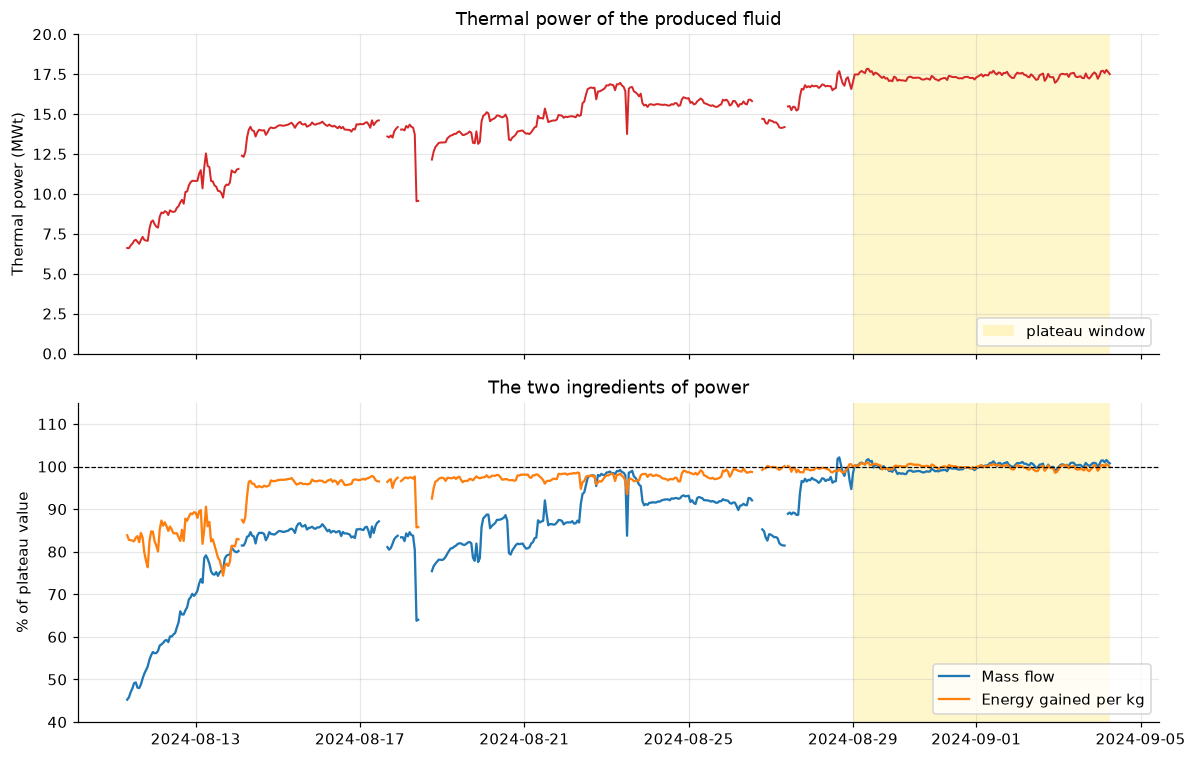

In [4]:
hp = tp.resample("1h").median()
hp["T"] = steady["T16B_corr_F"].resample("1h").median()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(hp.index, hp["power_MW"], color="tab:red", lw=1.3)
shade_window(ax[0], plateau.index.min(), plateau.index.max(), label="plateau window")
ax[0].set_ylabel("Thermal power (MWt)"); ax[0].set_ylim(0, 20)
ax[0].set_title("Thermal power of the produced fluid"); ax[0].legend(loc="lower right")

ax[1].plot(hp.index, hp["produced_kg_s"] / p["produced_kg_s"].median() * 100, color="tab:blue", label="Mass flow")
ax[1].plot(hp.index, hp["dh_kJ_kg"] / p["dh_kJ_kg"].median() * 100, color="tab:orange", label="Energy gained per kg")
ax[1].axhline(100, color="k", lw=0.8, ls="--")
shade_window(ax[1], plateau.index.min(), plateau.index.max())
ax[1].set_ylabel("% of plateau value"); ax[1].set_ylim(40, 115)
ax[1].set_title("The two ingredients of power"); ax[1].legend(loc="lower right")
savefig(fig, "04_thermal_power.png"); plt.show()

**Reading this:** power climbs from about 7 MW on the first day to about 17 MW on the plateau. In the lower panel, the **blue line (mass flow) moves much more** than the orange one (energy per kg): the water got somewhat hotter, but the big change is that *much more water is coming back*.

## 3. Why did the power grow?

We can split the growth into the two ingredients with logarithms. Because *power = mass × energy-per-kg*, taking logs turns the product into a sum:

$$\ln\frac{P_\text{end}}{P_\text{start}} = \ln\frac{\dot m_\text{end}}{\dot m_\text{start}} + \ln\frac{\Delta h_\text{end}}{\Delta h_\text{start}}$$

so each term is that ingredient's share of the growth, and the shares add up exactly.

Our starting point is the **first day the producer temperature exceeded 360 °F**, so we compare "hot and flowing" with "hot and flowing, later", instead of including the initial warm-up.

In [5]:
dly = pd.DataFrame({
    "T": steady["T16B_corr_F"],
    "m": tp["produced_kg_s"],
    "dh": tp["dh_kJ_kg"],
    "P": tp["power_MW"],
}).resample("1D").median().dropna()
dly.index.name = "date"

ref_day = dly.index[dly["T"] >= 360][0]
ref = dly.loc[ref_day]
m_end, dh_end = p["produced_kg_s"].median(), p["dh_kJ_kg"].median()

P_ref = ref["m"] * ref["dh"] / 1000
P_end = m_end * dh_end / 1000
share_m = np.log(m_end / ref["m"])
share_h = np.log(dh_end / ref["dh"])
total = share_m + share_h

print(f"Starting day (first above 360 °F): {ref_day.date()}   power {P_ref:.1f} MW")
print(f"Plateau                          :                   power {P_end:.1f} MW   ({(P_end/P_ref-1)*100:+.0f}%)\n")
print(f"  more water coming back : mass flow {ref['m']:.1f} -> {m_end:.1f} kg/s  accounts for {share_m/total*100:.0f}% of the growth")
print(f"  hotter water           : energy/kg {ref['dh']:.0f} -> {dh_end:.0f} kJ/kg  accounts for {share_h/total*100:.0f}% of the growth")

Starting day (first above 360 °F): 2024-08-14   power 13.9 MW
Plateau                          :                   power 17.4 MW   (+25%)

  more water coming back : mass flow 20.0 -> 23.9 kg/s  accounts for 79% of the growth
  hotter water           : energy/kg 694 -> 727 kJ/kg  accounts for 21% of the growth


About **80%** of the power growth after the temperature stabilised came from **more water returning** (the efficiency improving, as we saw in notebook 03), and only about **20%** from the water being hotter.

> **Learn:** this kind of "how much of the change is due to each factor" breakdown is called an *attribution* or *decomposition*. It is a powerful way to turn a plot into an explanation.

## 4. Did the power decline?

Now the question in the notebook's name. Two things could cause decline:
- the **rock cools** along the flow path, so the water comes out cooler, or
- **less water returns**.

Over the plateau week, we fit a straight line through the *daily* values of power and temperature. (We use daily values rather than 30-second ones, because neighbouring readings are strongly related and would make the fit look far more certain than it is.)

In [6]:
dd = dly.loc[str(plateau_start):]
x = np.arange(len(dd))                              # day number: 0, 1, 2, ...
tcrit = stats.t.ppf(0.975, len(dd) - 2)             # for a 95% confidence interval with few points

rows = []
for col, label, unit in [("P", "Thermal power", "MW/day"), ("T", "Temperature", "°F/day"), ("m", "Produced mass flow", "kg/s per day")]:
    fit = stats.linregress(x, dd[col])
    rows.append({"quantity": label, "trend": fit.slope, "95% range low": fit.slope - tcrit * fit.stderr,
                 "95% range high": fit.slope + tcrit * fit.stderr, "unit": unit, "p-value": fit.pvalue})
trends = pd.DataFrame(rows).set_index("quantity")
print(f"Plateau: {len(dd)} daily values, {dd.index.min().date()} to {dd.index.max().date()}\n")
trends.round(3)

Plateau: 7 daily values, 2024-08-29 to 2024-09-04



,trend,95% range low,95% range high,unit,p-value
quantity,,,,,
Thermal power,0.035,-0.028,0.099,MW/day,0.208
Temperature,-0.176,-0.552,0.201,°F/day,0.284
Produced mass flow,0.062,-0.009,0.133,kg/s per day,0.074


> **Learn:** `stats.linregress` gives the slope of the best straight line and its uncertainty. A **95% range** means: if we repeated the experiment many times, 95% of ranges built this way would contain the true slope. A **p-value** above about 0.05 means "we cannot tell this slope apart from zero".

**Reading the table:** for power, the range for the trend runs from slightly negative to positive, and the p-value is large. For temperature, the same: the best-fit slope is slightly negative, but the range comfortably includes zero. **We cannot detect any decline.** We can even put a limit on it, which we do next.

Any change in power over the plateau week is between -1.1% and +4.0% per week (95% range).
So a decline faster than about 1.1% per week is ruled out by the data.



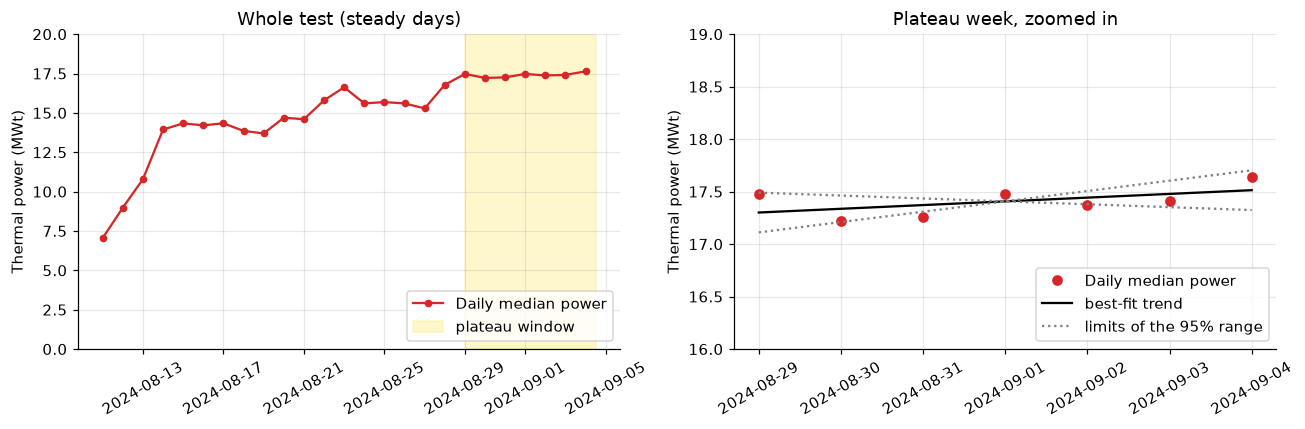

In [7]:
fit = stats.linregress(x, dd["P"])
lo, hi = fit.slope - tcrit * fit.stderr, fit.slope + tcrit * fit.stderr
mean_P = dd["P"].mean()
print(f"Any change in power over the plateau week is between {lo/mean_P*100*7:+.1f}% and {hi/mean_P*100*7:+.1f}% per week (95% range).")
print(f"So a decline faster than about {abs(lo)/mean_P*100*7:.1f}% per week is ruled out by the data.\n")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(dly.index, dly["P"], "o-", color="tab:red", ms=4, label="Daily median power")
ax[0].axvspan(pd.Timestamp(plateau_start), dly.index.max() + pd.Timedelta("12h"), color="gold", alpha=0.2, label="plateau window")
ax[0].set_ylabel("Thermal power (MWt)"); ax[0].set_ylim(0, 20); ax[0].set_title("Whole test (steady days)")
ax[0].tick_params(axis="x", rotation=30); ax[0].legend(loc="lower right")

ax[1].plot(dd.index, dd["P"], "o", color="tab:red", label="Daily median power")
xx = np.array([0, len(dd) - 1])
ax[1].plot(dd.index[xx], fit.intercept + fit.slope * xx, color="k", label="best-fit trend")
for sl, ls in [(lo, ":"), (hi, ":")]:
    ax[1].plot(dd.index[xx], mean_P + sl * (xx - x.mean()), color="gray", ls=ls)
ax[1].plot([], [], color="gray", ls=":", label="limits of the 95% range")
ax[1].set_ylim(16, 19); ax[1].set_ylabel("Thermal power (MWt)"); ax[1].set_title("Plateau week, zoomed in")
ax[1].tick_params(axis="x", rotation=30); ax[1].legend(loc="lower right")
savefig(fig, "04_decline_test.png"); plt.show()

### What the data can and cannot say

- **What we can say:** during the plateau week the thermal power showed **no decline**. The data rule out a decline faster than about 1% per week, and allow anything from that up to a *rise* of about 4% per week. The temperature trend was also indistinguishable from zero (best fit -0.18 °F/day, range -0.55 to +0.20 °F/day).
- **What we cannot say:** whether the system will decline over months or years. Cooling of the rock around the flow path develops **slowly**, and a four-week test with a seven-day plateau is far too short to see it. A flat week is *not* evidence that decline will never happen.

### The apparent dip on 24 to 27 August
Look at the left plot: power dipped by 6 to 8% around 24 to 27 Aug. This is easy to mistake for decline, so let's check what caused it:

In [8]:
dip = dly.loc["2024-08-23":"2024-08-28", ["T", "m", "P"]].copy()
dip["P change vs 23 Aug (%)"] = (dip["P"] / dip.loc["2024-08-23", "P"] - 1) * 100
dip["m change vs 23 Aug (%)"] = (dip["m"] / dip.loc["2024-08-23", "m"] - 1) * 100
dip["T change vs 23 Aug (°F)"] = dip["T"] - dip.loc["2024-08-23", "T"]
dip[["P change vs 23 Aug (%)", "m change vs 23 Aug (%)", "T change vs 23 Aug (°F)"]].round(1)

,P change vs 23 Aug (%),m change vs 23 Aug (%),T change vs 23 Aug (°F)
date,,,
2024-08-23,0.0,0.0,0.0
2024-08-24,-6.1,-6.2,-0.3
2024-08-25,-5.7,-6.4,1.5
2024-08-26,-6.2,-7.6,4.2
2024-08-27,-8.1,-9.8,5.5
2024-08-28,0.9,-1.3,5.1


The temperature **did not fall** during the dip (it rose by up to about 5 °F by 26 to 27 Aug), while the mass flow fell by 6 to 10%. So the dip was **less water returning**, right after the pump rate was changed on 24 Aug and again on 26 Aug (see notebook 03), and not cooling of the rock. The flow recovered within days.

This is exactly why it matters to ask *what* declined, not just *whether* power declined.

## 5. How much heat did the test produce?

Power × time = energy. Adding up the power in every 30-second row (each row is 30 s = 1/120 of an hour) gives the total heat produced, in **megawatt-hours thermal (MWh)**.

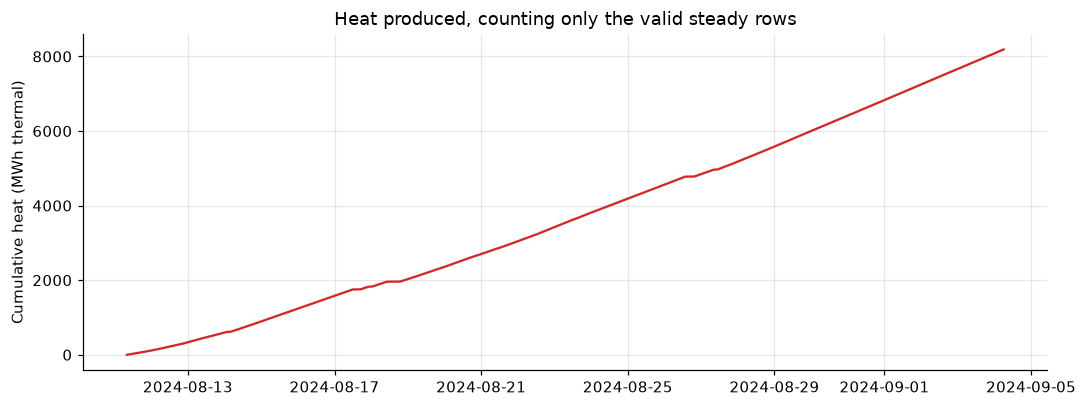

Rows counted : 65,856  (549 hours = 22.9 days)
Heat produced: 8,187 MWh thermal  =  29,474 GJ


In [9]:
hours_per_row = 30 / 3600
energy_MWh = (tp["power_MW"] * hours_per_row).fillna(0).cumsum()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(energy_MWh.index, energy_MWh.values, color="tab:red")
ax.set_ylabel("Cumulative heat (MWh thermal)"); ax.set_title("Heat produced, counting only the valid steady rows")
savefig(fig, "04_cumulative_energy.png"); plt.show()

total_MWh = energy_MWh.iloc[-1]
print(f"Rows counted : {len(steady):,}  ({len(steady) * hours_per_row:.0f} hours = {len(steady) * hours_per_row / 24:.1f} days)")
print(f"Heat produced: {total_MWh:,.0f} MWh thermal  =  {total_MWh * 3.6:,.0f} GJ")

This is a **lower bound**: we left out the pump stops, the settling periods after them, and the start-up and wind-down phases. The true total for the whole test is somewhat larger.

> **Learn:** `.cumsum()` keeps a running total down a column, and `.fillna(0)` replaces missing values with zero so one gap cannot break the sum.

## 6. How sure are we? (sensitivity analysis)

As in notebook 03, we change one assumption at a time. But the answer is different this time. Remember that the injection water temperature barely mattered for *efficiency*. For *power* it enters directly, because it sets the energy of the water going in.

In [10]:
cal, const = load_flow_calibration(), load_constants()
_, T_spread, _ = temperature_offset(load_manual_tp())

def shifted(dT):
    f = plateau.copy(); f["T16B_corr_F"] = f["T16B_corr_F"] + dT; return f

def power(frame, **kw):
    return thermal_power(frame, **kw)["power_MW"].median()

base = power(plateau)
scen = pd.Series({
    "Injection water 10 °C":                    power(plateau, T_inj_C=10),
    "Injection water 30 °C":                    power(plateau, T_inj_C=30),
    "Calibration through the origin":           power(recalibrate_through_origin(plateau, const, cal)),
    f"Temperature offset -{T_spread:.1f} °F":   power(shifted(-T_spread)),
    f"Temperature offset +{T_spread:.1f} °F":   power(shifted(+T_spread)),
    "Raw temperature (no correction)":          power(plateau, T_col="T16B_F"),
    "Steam fixed at 19.6% of total (report)":   power(plateau, steam_x=0.196),
    "Steam 19.6% added to the liquid":          power(plateau, steam_x=0.196 / 1.196),
})
table = pd.DataFrame({"power (MWt)": scen, "change vs base (%)": (scen / base - 1) * 100})
print(f"BASE CASE: {base:.1f} MWt\n")
table.round(1)

BASE CASE: 17.3 MWt



,power (MWt),change vs base (%)
Injection water 10 °C,18.4,5.8
Injection water 30 °C,16.3,-5.8
Calibration through the origin,17.7,2.1
Temperature offset -4.6 °F,17.0,-2.1
Temperature offset +4.6 °F,17.7,2.2
Raw temperature (no correction),16.4,-5.3
Steam fixed at 19.6% of total (report),17.6,1.7
Steam 19.6% added to the liquid,17.0,-2.2


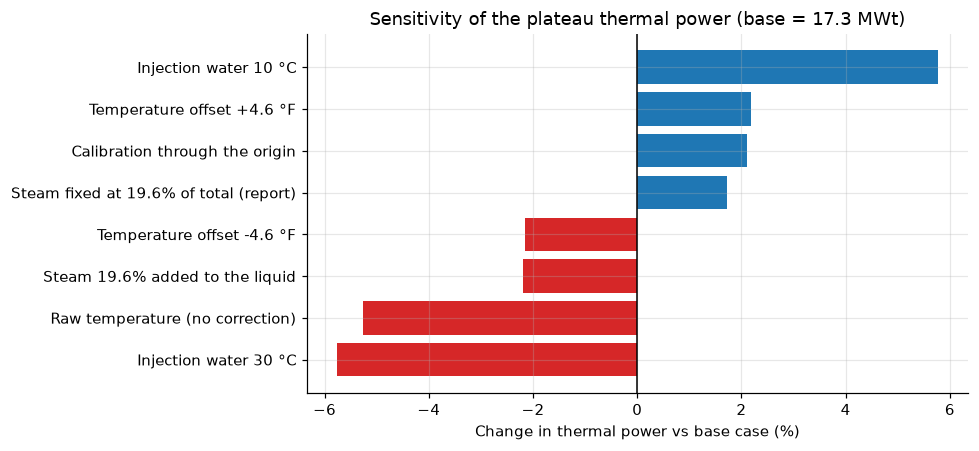

Across all scenarios the plateau power ranges from 16.3 to 18.4 MWt.


In [11]:
change = ((scen / base - 1) * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(change.index, change.values, color=["tab:red" if v < 0 else "tab:blue" for v in change.values])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Change in thermal power vs base case (%)")
ax.set_title(f"Sensitivity of the plateau thermal power (base = {base:.1f} MWt)")
savefig(fig, "04_sensitivity.png"); plt.show()

print(f"Across all scenarios the plateau power ranges from {scen.min():.1f} to {scen.max():.1f} MWt.")

**Reading this:**
- The **injection water temperature is now the biggest uncertainty**: ±10 °C moves the power by about ±6%. It is not in our dataset (the report says it was measured, but we only have ambient pit water to go on). **If you can get a measured injection temperature, this is the single most useful refinement.**
- The **temperature correction** is next: using the raw thermocouple reading would cut the power by about 5%.
- Steam and calibration choices matter by about 2% each.

So the honest statement is **"about 17 MWt, plausibly 16 to 18"**.

## 7. Key results and saving

In [12]:
key = pd.Series({
    "plateau thermal power (MWt)": base,
    "plateau power, lowest scenario (MWt)": scen.min(),
    "plateau power, highest scenario (MWt)": scen.max(),
    "produced mass flow (kg/s)": m_out,
    "energy gained per kg (kJ/kg)": dh_end,
    "producer temperature, corrected (F)": T_out_F,
    "power at first day above 360 F (MWt)": P_ref,
    "growth since then (%)": (P_end / P_ref - 1) * 100,
    "share of growth from more water (%)": share_m / total * 100,
    "share of growth from hotter water (%)": share_h / total * 100,
    "plateau power trend (MW/day)": trends.loc["Thermal power", "trend"],
    "plateau power trend, 95% low (MW/day)": trends.loc["Thermal power", "95% range low"],
    "plateau power trend, 95% high (MW/day)": trends.loc["Thermal power", "95% range high"],
    "heat produced in steady rows (MWh thermal)": total_MWh,
}, name="value")

key.round(3).to_csv("../data/processed/power_key_results.csv", index_label="metric")
dly.round(3).to_csv("../data/processed/power_daily.csv")
hp[["power_MW", "produced_kg_s", "dh_kJ_kg", "T"]].round(3).to_csv("../data/processed/power_1h.csv", index_label="time")
key.round(2).to_frame()

,value
plateau thermal power (MWt),17.35
"plateau power, lowest scenario (MWt)",16.35
"plateau power, highest scenario (MWt)",18.35
produced mass flow (kg/s),23.93
energy gained per kg (kJ/kg),726.83
"producer temperature, corrected (F)",375.32
power at first day above 360 F (MWt),13.91
growth since then (%),24.99
share of growth from more water (%),79.40
share of growth from hotter water (%),20.60


## Summary

| Question | Answer |
|---|---|
| **Thermal power on the plateau** | **~17 MWt** (plausibly 16 to 18) |
| Energy gained per kg of water | ~727 kJ/kg (about 375 °F water from 68 °F water) |
| Power through the test | grew from ~7 MW (first day) to ~17 MW |
| What drove the growth | ~80% more water returning, ~20% hotter water |
| **Did it decline?** | **No decline detected.** A decline faster than ~1% per week is ruled out; the plateau week's change is between -1% and +4% per week |
| The dip on 24 to 27 Aug | caused by less water returning after pump-rate changes, not by cooling |
| Heat produced (steady rows only) | ~8,200 MWh thermal (a lower bound) |
| Biggest uncertainty | injection water temperature (±6% for ±10 °C) |

### Caveats to state in the README
- **No published power number to compare with.** Our check was against physics (the textbook formula agrees within about 1%), not against the report.
- **The injection temperature is assumed (20 °C).** It is the largest source of uncertainty.
- **Pressure effects on enthalpy are ignored** (a ~2% effect, and we treat injection and production consistently).
- **Four weeks cannot show long-term decline.** Our result is "no decline over the plateau week", which says nothing about years.
- **Thermal, not electrical.** Converting heat to electricity would deliver only a fraction (typically on the order of 10%, depending on the plant design). That conversion is an assumption outside this dataset.

### The notebook's name
We named it *power decline*, but the honest finding is that **power grew, then flattened**. In the README we'll describe it as *thermal power evolution*, and report that no decline was detected within the test duration.

**Next:** write the README (data source, method, results, caveats) and publish the project on GitHub.